# Cleaning Data

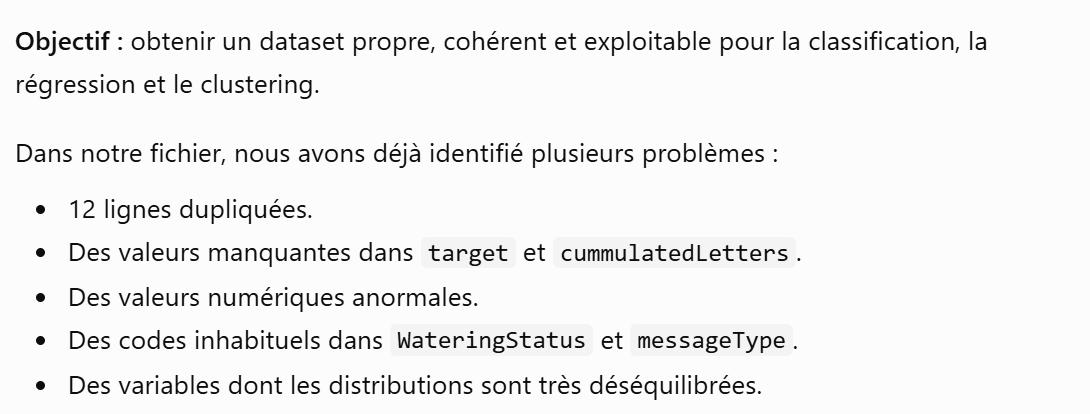

In [3]:
import pandas as pd
import numpy as np

df = pd.read_csv(
    r"C:\Users\pc\Documents\IA cours\projet\export_2023-12-31-23-00_to_2026-11-14-22-59.csv"
)

In [4]:

# Garder une copie originale
df_original = df.copy()

# Créer une copie pour le nettoyage
df_clean = df.copy()

print("Dataset original :", df_original.shape)
print("Dataset à nettoyer :", df_clean.shape)


Dataset original : (1562779, 15)
Dataset à nettoyer : (1562779, 15)


In [5]:

# Nombre de doublons
print("Nombre de doublons :", df_clean.duplicated().sum())


Nombre de doublons : 12


In [6]:

# Suppression des doublons
df_clean = df_clean.drop_duplicates()

print("Dimensions après suppression :", df_clean.shape)


Dimensions après suppression : (1562767, 15)


In [7]:

print("Valeurs disponibles dans target :")
print(df_clean["target"].value_counts(dropna=True))

print("\nNombre de valeurs manquantes :")
print(df_clean["target"].isna().sum())


Valeurs disponibles dans target :
target
50000.0    4350
0.0         937
55000.0      11
60000.0       6
Name: count, dtype: int64

Nombre de valeurs manquantes :
1557463


In [8]:

df_supervised = df_clean.dropna(subset=["target"]).copy()

print("Dataset supervisé :", df_supervised.shape)


Dataset supervisé : (5304, 15)


In [9]:

# Variables à analyser
variables = [
    "temp",
    "hum",
    "moistureLevel",
    "totalLitres",
    "pres",
    "waterFlow"
]

for col in variables:

    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df_clean[
        (df_clean[col] < lower) |
        (df_clean[col] > upper)
    ]

    print("\nVariable :", col)
    print("Q1 :", Q1)
    print("Q3 :", Q3)
    print("IQR :", IQR)
    print("Limite inférieure :", lower)
    print("Limite supérieure :", upper)
    print("Nombre d'outliers :", len(outliers))



Variable : temp
Q1 : 24.82
Q3 : 35.96
IQR : 11.14
Limite inférieure : 8.11
Limite supérieure : 52.67
Nombre d'outliers : 221235

Variable : hum
Q1 : 40.2
Q3 : 63.14
IQR : 22.939999999999998
Limite inférieure : 5.790000000000006
Limite supérieure : 97.55
Nombre d'outliers : 225368

Variable : moistureLevel
Q1 : 55.0
Q3 : 907.0
IQR : 852.0
Limite inférieure : -1223.0
Limite supérieure : 2185.0
Nombre d'outliers : 79

Variable : totalLitres
Q1 : 0.0
Q3 : 0.0
IQR : 0.0
Limite inférieure : 0.0
Limite supérieure : 0.0
Nombre d'outliers : 122429

Variable : pres
Q1 : 961.74
Q3 : 966.07
IQR : 4.330000000000041
Limite inférieure : 955.2449999999999
Limite supérieure : 972.565
Nombre d'outliers : 221811

Variable : waterFlow
Q1 : 0.0
Q3 : 0.0
IQR : 0.0
Limite inférieure : 0.0
Limite supérieure : 0.0
Nombre d'outliers : 6222


In [10]:

# Créer une copie pour le traitement
df_clean = df_clean.copy()

# Remplacer les mesures manifestement invalides par NaN
df_clean.loc[
    (df_clean["temp"] < -50) | (df_clean["temp"] > 100),
    "temp"
] = np.nan

df_clean.loc[
    (df_clean["hum"] < 0) | (df_clean["hum"] > 100),
    "hum"
] = np.nan

df_clean.loc[
    (df_clean["moistureLevel"] < 0) |
    (df_clean["moistureLevel"] > 1024),
    "moistureLevel"
] = np.nan

df_clean.loc[
    df_clean["pres"] < 0,
    "pres"
] = np.nan

# Vérification
print(df_clean[
    ["temp", "hum", "moistureLevel", "pres"]
].isna().sum())


temp             221192
hum                   2
moistureLevel       157
pres             221337
dtype: int64


In [11]:

print("WateringStatus :")
print(df_clean["WateringStatus"].value_counts())

print("\nMessageType :")
print(df_clean["messageType"].value_counts())


WateringStatus :
WateringStatus
0      1465740
1        97025
251          2
Name: count, dtype: int64

MessageType :
messageType
1             1562724
0                  41
1708058472          2
Name: count, dtype: int64


In [13]:

df_clean[
    df_clean["WateringStatus"] == 251
]


,source,datetime,id,messageType,temp,hum,moistureLevel,totalLitres,WateringStatus,pres,waterFlow,timestamp,theDate,cummulatedLetters,target
77198,dataNew,2025-04-28T14:44:59.706Z,771751936,1708058472,0.0,NaN,0.0,0.0,251,0.0,0.0,1745851499706,28/04/2025 15:44:59,NaN,NaN
77199,dataNew,2025-04-28T14:45:00.885Z,-1610612736,1708058472,0.0,NaN,0.0,0.0,251,0.0,0.0,1745851500885,28/04/2025 15:45:00,NaN,NaN


In [14]:

# Conversion en datetime
df_clean["datetime"] = pd.to_datetime(
    df_clean["datetime"],
    errors="coerce",
    utc=True
)

# Vérification
print(df_clean["datetime"].dtype)

print("\nPremière date :")
print(df_clean["datetime"].min())

print("\nDernière date :")
print(df_clean["datetime"].max())


datetime64[us, UTC]

Première date :
2025-04-21 16:00:38.194000+00:00

Dernière date :
2025-11-20 13:26:19.066000+00:00


In [15]:

print("Dimensions finales :", df_clean.shape)

print("\nDoublons restants :")
print(df_clean.duplicated().sum())

print("\nValeurs manquantes :")
print(df_clean.isnull().sum())

print("\nTypes des variables :")
print(df_clean.dtypes)


Dimensions finales : (1562767, 15)

Doublons restants :
0

Valeurs manquantes :
source                     0
datetime                   0
id                         0
messageType                0
temp                  221192
hum                        2
moistureLevel            157
totalLitres                0
WateringStatus             0
pres                  221337
waterFlow                  0
timestamp                  0
theDate                    0
cummulatedLetters     918823
target               1557463
dtype: int64

Types des variables :
source                               str
datetime             datetime64[us, UTC]
id                                 int64
messageType                        int64
temp                             float64
hum                              float64
moistureLevel                    float64
totalLitres                      float64
WateringStatus                     int64
pres                             float64
waterFlow                        float6

In [16]:

df_clean.to_csv(
    "dataset_cleaned.csv",
    index=False
)

print("Dataset nettoyé sauvegardé !")


Dataset nettoyé sauvegardé !


### Étape 3 : Data Cleaning

Cette étape consiste à améliorer la qualité des données avant leur utilisation dans les modèles de Machine Learning.

Les opérations réalisées sont :

1. **Suppression des doublons :** identification et suppression de 12 observations dupliquées.
2. **Analyse des valeurs manquantes :** identification de deux variables particulièrement concernées, `target` (99,66 %) et `cummulatedLetters` (58,79 %).
3. **Détection des valeurs aberrantes :** utilisation de la méthode IQR pour identifier les observations inhabituelles.
4. **Traitement des anomalies :** remplacement des mesures manifestement invalides par des valeurs manquantes, sans supprimer les observations entières.
5. **Conversion temporelle :** transformation de `datetime` en format datetime pour faciliter les analyses temporelles.

Le dataset obtenu constitue une première version nettoyée. Certaines règles de validation des capteurs restent à confirmer à partir de la documentation technique.